In [8]:
import pandas as pd

file_path = "data/smsspamcollection/SMSSpamCollection"

df = pd.read_csv(
    file_path,
    sep="\t",
    header=None,
    names=["label", "message"]
)

df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [10]:
print("Shape:", df.shape)
print("\nLabels:")
print(df["label"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

Shape: (5572, 2)

Labels:
label
ham     4825
spam     747
Name: count, dtype: int64

Missing values:
label      0
message    0
dtype: int64


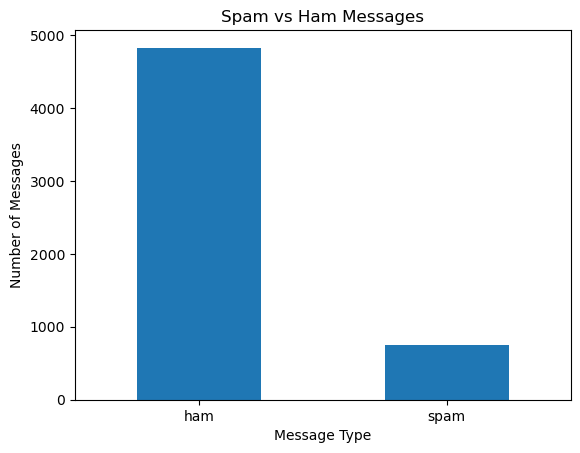

In [11]:
import matplotlib.pyplot as plt

df["label"].value_counts().plot(kind="bar")

plt.title("Spam vs Ham Messages")
plt.xlabel("Message Type")
plt.ylabel("Number of Messages")
plt.xticks(rotation=0)
plt.show()

In [12]:
print("Sample HAM messages:")
display(df[df["label"] == "ham"]["message"].head(5))

print("\nSample SPAM messages:")
display(df[df["label"] == "spam"]["message"].head(5))

Sample HAM messages:


0    Go until jurong point, crazy.. Available only ...
1                        Ok lar... Joking wif u oni...
3    U dun say so early hor... U c already then say...
4    Nah I don't think he goes to usf, he lives aro...
6    Even my brother is not like to speak with me. ...
Name: message, dtype: object


Sample SPAM messages:


2     Free entry in 2 a wkly comp to win FA Cup fina...
5     FreeMsg Hey there darling it's been 3 week's n...
8     WINNER!! As a valued network customer you have...
9     Had your mobile 11 months or more? U R entitle...
11    SIX chances to win CASH! From 100 to 20,000 po...
Name: message, dtype: object

In [13]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-zA-Z0-9\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_message"] = df["message"].apply(clean_text)

df[["message", "clean_message"]].head()

,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i dont think he goes to usf he lives aroun...


In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer()

X = vectorizer.fit_transform(df["clean_message"])

y = df["label"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (5572, 9541)
y shape: (5572,)


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 4457
Testing samples: 1115


In [16]:
from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB()

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [17]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9524663677130045

Classification Report:
              precision    recall  f1-score   support

         ham       0.95      1.00      0.97       966
        spam       1.00      0.64      0.78       149

    accuracy                           0.95      1115
   macro avg       0.97      0.82      0.88      1115
weighted avg       0.95      0.95      0.95      1115


Confusion Matrix:
[[966   0]
 [ 53  96]]


In [18]:
TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

,input,'content'
,encoding,'utf-8'
,decode_error,'strict'
,strip_accents,None
,lowercase,True
,preprocessor,None
,tokenizer,None
,analyzer,'word'
,stop_words,None
,token_pattern,'(?u)\\b\\w\\w+\\b'
,ngram_range,"(1, ...)"


In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer_2 = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

X_2 = vectorizer_2.fit_transform(df["clean_message"])

print("New X shape:", X_2.shape)

New X shape: (5572, 14794)


In [20]:
from sklearn.model_selection import train_test_split

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X_2,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X2_train.shape[0])
print("Testing samples:", X2_test.shape[0])

Training samples: 4457
Testing samples: 1115


In [21]:
from sklearn.naive_bayes import MultinomialNB

model_2 = MultinomialNB()

model_2.fit(X2_train, y2_train)

print("Improved model trained successfully!")

Improved model trained successfully!


In [22]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y2_pred = model_2.predict(X2_test)

print("Accuracy:", accuracy_score(y2_test, y2_pred))

print("\nClassification Report:")
print(classification_report(y2_test, y2_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y2_test, y2_pred))

Accuracy: 0.9605381165919282

Classification Report:
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       966
        spam       1.00      0.70      0.83       149

    accuracy                           0.96      1115
   macro avg       0.98      0.85      0.90      1115
weighted avg       0.96      0.96      0.96      1115


Confusion Matrix:
[[966   0]
 [ 44 105]]


In [23]:
import joblib

joblib.dump(model_2, "model/spam_model.pkl")
joblib.dump(vectorizer_2, "model/tfidf_vectorizer.pkl")

print("Model and vectorizer saved successfully!")

Model and vectorizer saved successfully!
